# Club analytics with SQL
**Question.** Which plans earn the most, which lose members fastest, when is the club busiest, and who should staff call this week?

**Data.** A synthetic SQLite database (`build_db.py`) with three tables: `members`, `visits`, and `payments`. All values are invented; no real member appears. The SQL lives in `queries.sql`; this notebook runs each query and charts a few.

In [1]:
import sqlite3, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
con = sqlite3.connect("club.db")
queries = [q.strip() for q in open("queries.sql").read().split(";") if "SELECT" in q]
pd.read_sql("SELECT (SELECT COUNT(*) FROM members) AS members, (SELECT COUNT(*) FROM visits) AS visits, (SELECT COUNT(*) FROM payments) AS payments", con)

,members,visits,payments
0,800,25951,800


## Query 1: revenue by plan (active members)

In [2]:
q1 = pd.read_sql(queries[0], con); q1

,plan,active_members,monthly_revenue
0,Family,109,11990
1,Single,158,8690
2,Couple,76,6840
3,Senior,104,4160
4,Junior,47,1410


## Query 2: churn by plan

In [3]:
q2 = pd.read_sql(queries[1], con); q2

,plan,churn_pct,members
0,Family,42.3,189
1,Couple,42.0,131
2,Single,37.8,254
3,Junior,36.5,74
4,Senior,31.6,152


## Query 3: busiest hours

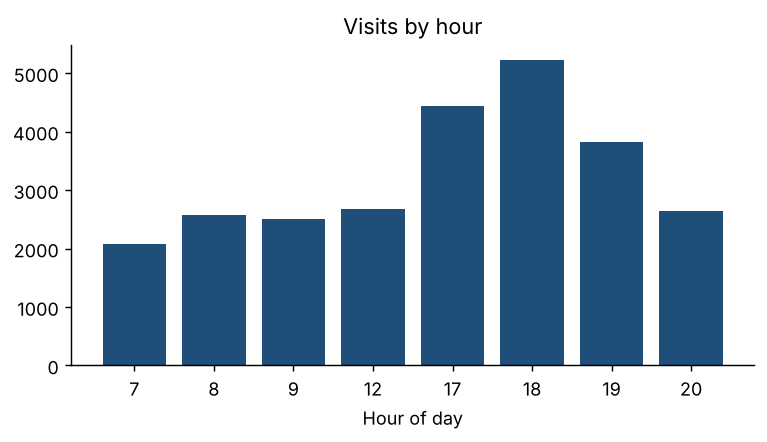

,hour,visits
7,7,2071
5,8,2572
6,9,2509
3,12,2672
1,17,4441
0,18,5224
2,19,3825
4,20,2637


In [4]:
q3 = pd.read_sql(queries[2], con).sort_values("hour")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(q3.hour.astype(str), q3.visits, color="#1f4e79"); ax.set_xlabel("Hour of day"); ax.set_title("Visits by hour")
plt.tight_layout(); plt.savefig("figures/hours.png"); plt.show()
q3

## Query 4: engagement by status

In [5]:
pd.read_sql(queries[3], con)

,status,visits_per_member_per_month
0,active,3.65
1,canceled,1.14
2,expired,1.20


## Query 5: outreach list (active members quiet for 60+ days)

In [6]:
pd.read_sql(queries[4], con)

,member_id,plan,last_visit
0,317,Senior,2026-07-18
1,468,Junior,2026-08-10
2,506,Senior,2026-08-14
3,48,Family,2026-08-22
4,104,Single,2026-08-25
5,622,Senior,2026-08-25
6,309,Family,2026-08-26
7,548,Couple,2026-08-26
8,670,Senior,2026-08-26
9,384,Single,2026-08-28


## Notes
* Joins (`members` to `payments` and `visits`), grouping, `HAVING`, and date arithmetic are all in `queries.sql`.
* Revenue uses each member's plan fee at first payment, so it ignores discounts and price changes.
* Synthetic data: the point is the SQL workflow, not the specific numbers.